# Monte Carlo plots: percentiles and the cumulative plot

Throwaway notebook to try the new behaviour before the docs are updated:

- `plot_monte_carlo` and the new `plot_monte_carlo_cumulative` mark **P10, P50, P90** by default, with the values in the legend.
- The normal fit is now **off** by default (`show_fit=True` brings it back), since Monte Carlo results need not be normal.
- Both take one result/Plant/array, or a list of them.

In [1]:
import numpy as np
from openpytea import (Equipment, Plant, monte_carlo,
                       plot_monte_carlo, plot_monte_carlo_cumulative)

## Two small hydrogen plants

Plant B has pricier equipment but makes 10% more hydrogen. Electricity and hydrogen prices are uncertain (hydrogen around 150 USD/unit, so NPV straddles zero).

In [2]:
def make_plant(name, reactor_cost, pump_cost, production):
    return Plant({
        "plant_name": name,
        "process_type": "Fluids",
        "country": "United States",
        "region": "Gulf Coast",
        "currency": "USD",
        "interest_rate": 0.08,
        "project_lifetime": 20,
        "plant_utilization": 0.9,
        "tax_rate": 0.25,
        "operator_hourly_rate": {"rate": 25},
        "equipment": [
            Equipment(name="Reactor", param=1.0, process_type="Fluids",
                      category="Reactors", purchased_cost=reactor_cost, cost_year=2024),
            Equipment(name="Pump", param=1.0, process_type="Fluids",
                      category="Pumps", purchased_cost=pump_cost, cost_year=2024),
        ],
        "variable_opex_inputs": {
            "electricity": {"consumption": 100, "price": 0.08,
                            "price_uncertainty": {"std": 0.02, "min": 0.03, "max": 0.15}},
            "water": {"consumption": 10, "price": 0.5},
        },
        "plant_products": {
            "hydrogen": {"production": production, "price": 150.0,
                         "price_uncertainty": {"std": 30.0, "min": 80.0, "max": 220.0}},
        },
    })

plant_a = make_plant("Plant A", 100_000, 20_000, 50)
plant_b = make_plant("Plant B", 150_000, 25_000, 55)

mc_a = monte_carlo(plant_a, num_samples=20_000, batch_size=20_000, random_seed=1)
mc_b = monte_carlo(plant_b, num_samples=20_000, batch_size=20_000, random_seed=1)

Monte Carlo:   0%|          | 0/1 [00:00<?, ?it/s]

Monte Carlo:   0%|          | 0/1 [00:00<?, ?it/s]

## One plant

Defaults: histogram with dashed lines at P10/P50/P90, and the same three values on the cumulative curve, with guide lines to both axes.

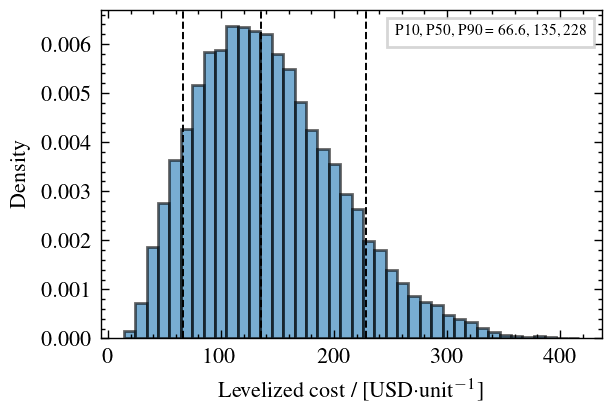

In [3]:
fig, ax = plot_monte_carlo(mc_a, metric="LCOP", bins=40)

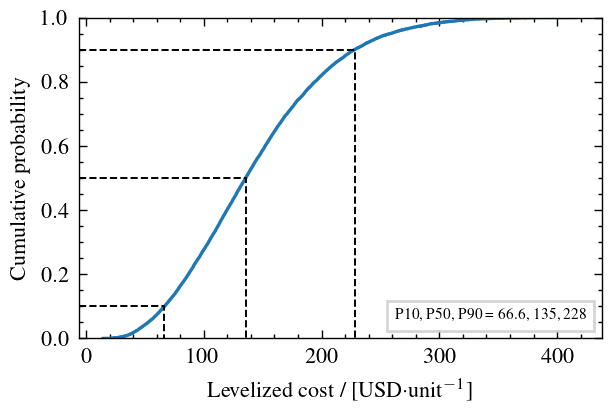

In [4]:
fig, ax = plot_monte_carlo_cumulative(mc_a, metric="LCOP")

Check: the legend values are plain `np.percentile` (P90 = the value 90% of samples are at or below).

In [5]:
np.percentile(mc_a["metrics"]["LCOP"], [10, 50, 90]).round(1)

array([ 66.6, 135.5, 228.1])

## Two plants

One line per plant in the legend, under a shared `P10, P50, P90` header. On the cumulative plot, a dot marks where each curve crosses the dashed 0.1 / 0.5 / 0.9 levels.

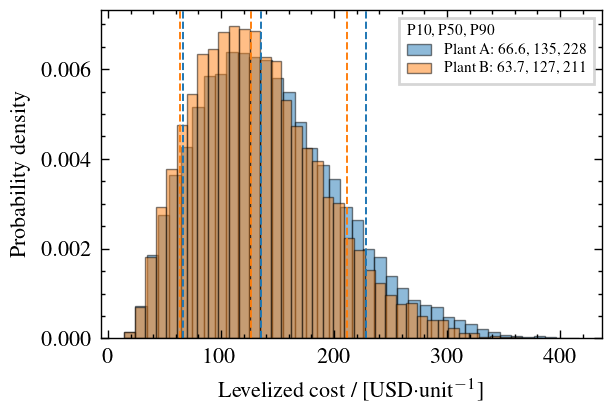

In [6]:
fig, ax = plot_monte_carlo([mc_a, mc_b], metric="LCOP", bins=40)

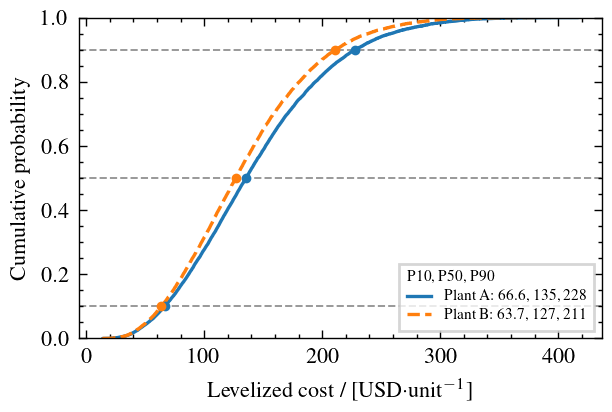

In [7]:
fig, ax = plot_monte_carlo_cumulative([mc_a, mc_b], metric="LCOP")

Large values share one power of ten, shown in the header (here NPV in millions). Plants work as well as result dicts.

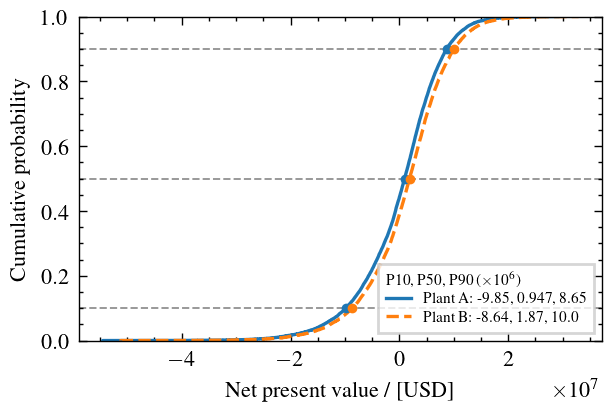

In [8]:
fig, ax = plot_monte_carlo_cumulative([plant_a, plant_b], metric="NPV")

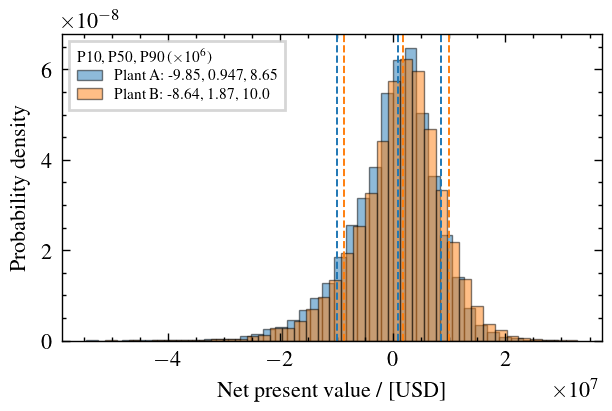

In [9]:
fig, ax = plot_monte_carlo([plant_a, plant_b], metric="NPV", bins=40)

## Options

Other percentiles:

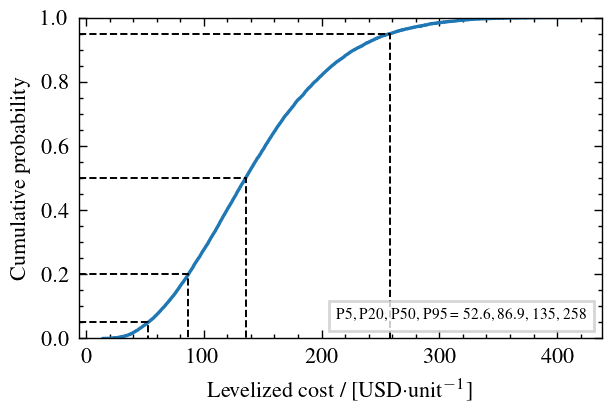

In [10]:
fig, ax = plot_monte_carlo_cumulative(mc_a, metric="LCOP", percentiles=(5, 20, 50, 95))

No percentiles (a plain histogram / curve):

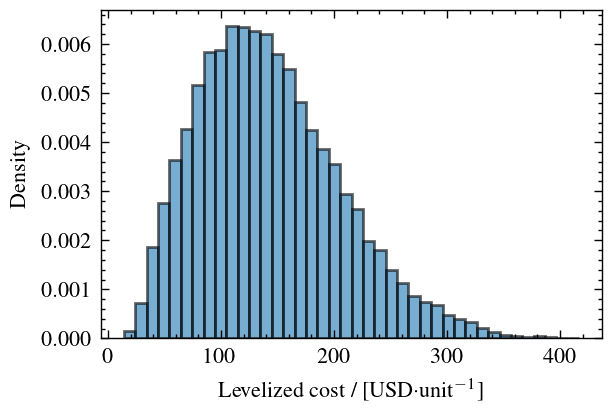

In [11]:
fig, ax = plot_monte_carlo(mc_a, metric="LCOP", bins=40, percentiles=None)

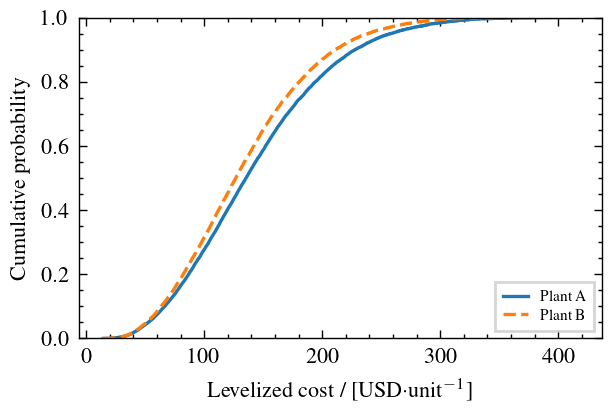

In [12]:
fig, ax = plot_monte_carlo_cumulative([mc_a, mc_b], metric="LCOP", percentiles=None)

The normal fit back on, together with the percentiles:

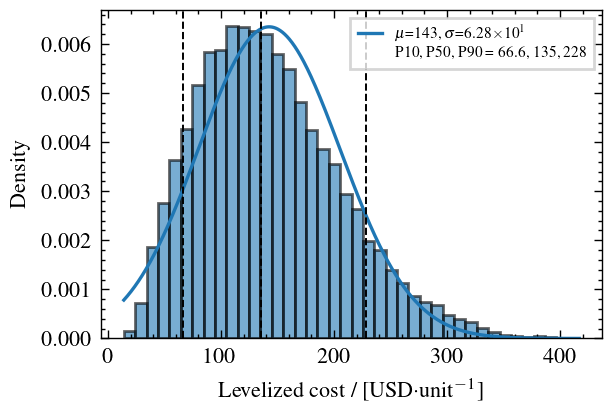

In [13]:
fig, ax = plot_monte_carlo(mc_a, metric="LCOP", bins=40, show_fit=True)

## Reading other probabilities

The returned `ax` is ordinary matplotlib, so further marks are one line, e.g. the break-even line on NPV:

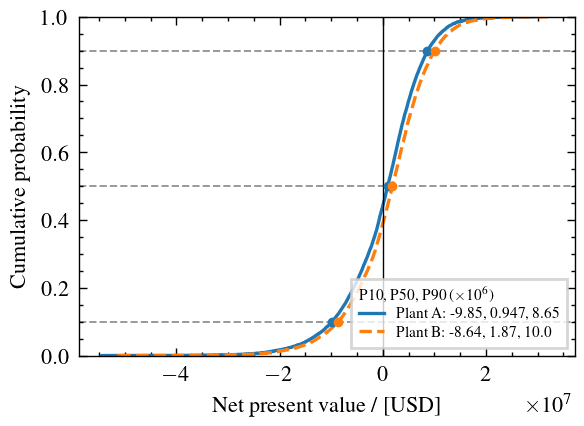

In [14]:
fig, ax = plot_monte_carlo_cumulative([mc_a, mc_b], metric="NPV", show=False)
ax.axvline(0, color="black", linewidth=0.5)

In [15]:
for name, mc in [("Plant A", mc_a), ("Plant B", mc_b)]:
    npv = np.asarray(mc["metrics"]["NPV"])
    print(f"{name}: P(NPV < 0) = {np.mean(npv < 0):.1%}")

Plant A: P(NPV < 0) = 44.3%
Plant B: P(NPV < 0) = 39.0%


## Deprecated function, for comparison

`plot_multiple_monte_carlo` still draws exactly what it did before (fit on, no percentiles) and warns that it goes in 4.0.

C:\Users\pbtamarona\AppData\Local\Temp\ipykernel_35784\2639030885.py:2: FutureWarning: plot_multiple_monte_carlo is deprecated and will be removed in OpenPyTEA 4.0; use plot_monte_carlo, which now accepts a list.
  fig, ax = plot_multiple_monte_carlo([mc_a, mc_b], metric="LCOP", bins=40)


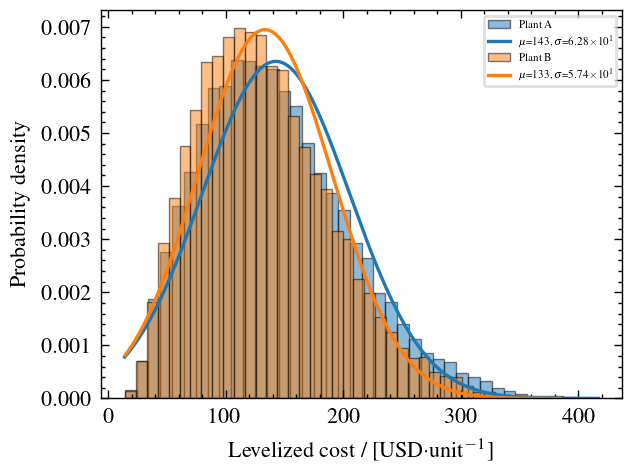

In [16]:
from openpytea import plot_multiple_monte_carlo
fig, ax = plot_multiple_monte_carlo([mc_a, mc_b], metric="LCOP", bins=40)